![Banner](../images/09_04_banner_rs_uav.png)


# RGB + NIR Multispectral Analysis

Adding a near-infrared camera to an RGB drone unlocks NDVI and its relatives: healthy leaves
reflect NIR strongly and absorb red, a contrast no visible-band index can match.


## Overview

A two-camera rig brings two problems a single multispectral sensor hides. The cameras see slightly different footprints, so the bands must be **co-registered**, and they record raw digital numbers (DN), not reflectance, so indices are **relative** unless the images are calibrated against reference panels. This notebook works through both on the paired Canola, Drybean, Wheat and Lentil-Wheat crop sets, then follows NDVI through the season for each crop.


## Core concepts

### Learning objectives

1. Measure and remove the misalignment between NIR and RGB frames with feature matching
   (ORB/SIFT + RANSAC homography) and ECC refinement (`rs.uav.coregister`).
2. Compute NDVI, GNDVI and SAVI from a registered pair and compare NDVI with ExG.
3. Explain relative vs calibrated reflectance and apply panel calibration, the empirical line
   method and irradiance normalisation (`rs.uav.panel_calibration`, `empirical_line`,
   `sunshine_normalize`).
4. Build NDVI trajectories across flight dates for four crops.

### Data

| Data | Type |
|---|---|
| Paired RGB/NIR PNG crops: Canola (4 dates), Drybean (6), Wheat (3), Lentil-Wheat (2) | **Real**, relative DN (no panels, GSD or licence on file) |
| Calibration-panel example in Section 5 | **Simulated** |

### Contents

1. Setup
2. How far apart are the two cameras?
3. Co-registration
4. NDVI, GNDVI and SAVI
5. Relative vs calibrated reflectance
6. NDVI trajectories for four crops
7. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled arrays
import matplotlib.pyplot as plt  # figures

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_04_uav")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

cat = rs.uav.build_catalog(DATA)
pairs = rs.uav.pair_catalog(cat[~cat.dataset.str.startswith("infra")])  # crop sets only
print(len(pairs), "RGB/NIR pairs in", pairs.session.nunique(), "sessions")

8970 RGB/NIR pairs in 15 sessions


## How far apart are the two cameras?

Load one Canola pair without registration and estimate the homography that maps NIR onto the
green band. Its translation terms are the offset in pixels; the diagonal terms are the scale
difference between the two lenses.


In [2]:
r = pairs[pairs.session == "canola_06082019"].iloc[5]
raw = rs.uav.load_pair(r.rgb_path, r.nir_path, register=False)
green, nir = raw.sel(band="green").values, raw.sel(band="nir").values

H, info = rs.uav.estimate_homography(nir, green, method="orb")
print(info)
print("homography:\n", np.round(H, 4))
print(f"shift: dx = {H[0, 2]:.1f} px, dy = {H[1, 2]:.1f} px; scale x = {H[0, 0]:.4f}, y = {H[1, 1]:.4f}")

{'method': 'orb', 'matches': 65, 'inliers': 44, 'rmse_px': 1.0241508483886719}
homography:
 [[ 1.0074e+00 -2.0000e-04 -2.1117e+00]
 [ 1.8000e-03  1.0017e+00 -8.0560e-01]
 [ 0.0000e+00  0.0000e+00  1.0000e+00]]
shift: dx = -2.1 px, dy = -0.8 px; scale x = 1.0074, y = 1.0017


## Co-registration

`rs.uav.coregister(moving, reference)` fits the homography (ORB or SIFT features, Lowe's ratio
test, RANSAC), optionally refines it with the Enhanced Correlation Coefficient (ECC) method
(kept only if it improves the match), and warps the moving band. `load_pair(...,
register=True)` does the same inside the loader.

Pixel correlation between NIR and green is not a fair score (the bands respond differently to
leaves and soil), so alignment is judged by how well their **edges** coincide:
`rs.uav.edge_agreement` correlates the Sobel edge maps and ignores the empty border a warp
leaves behind. `coregister` uses the same score to **validate** its own answer: a solution
with too few inliers, an implausibly large shift, or edges that agree less than before is
rejected and the band is returned unwarped (`info["accepted"]` is then False).


In [3]:
def edges(a):
    """Gradient magnitude, rescaled to 0-1 (for overlays)."""
    gy, gx = np.gradient(np.nan_to_num(a))
    m = np.hypot(gx, gy)
    return np.clip(m / np.percentile(m, 99), 0, 1)

aligned, reg = rs.uav.coregister(nir, green, method="sift", refine=True)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in reg.items() if k != "H"})

{'method': 'sift', 'matches': 98, 'inliers': 86, 'rmse_px': 0.557, 'accepted': True, 'reason': '', 'shift_px': 0.521, 'edge_before': 0.472, 'edge_after': 0.547, 'correlation': 0.142}


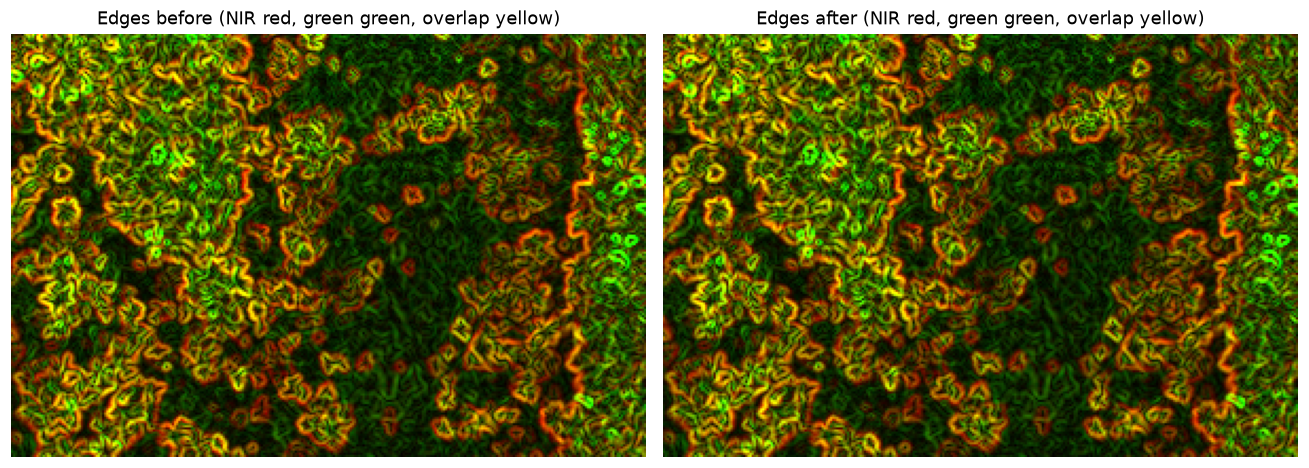

In [4]:
win = (slice(250, 450), slice(400, 700))  # zoom window (rows, cols)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, band, title in [(axes[0], nir, "before"), (axes[1], aligned, "after")]:
    ax.imshow(np.dstack([edges(band)[win], edges(green)[win], np.zeros_like(green[win])]))
    ax.set_title(f"Edges {title} (NIR red, green green, overlap yellow)"); ax.axis("off")
plt.tight_layout(); plt.show()

The shift is only a couple of pixels, but the scale term (about 0.7 %) adds up to several
pixels at the frame edges, which is where the overlay improves most.

Below, the three methods are compared on three pairs per crop **with validation switched
off**, to see what each would do on its own, and then with validation on.


In [5]:
rows = []
for crop, d in pairs.groupby("crop"):
    for _, rr in d.sample(3, random_state=1).iterrows():
        p = rs.uav.load_pair(rr.rgb_path, rr.nir_path)
        g, n = p.sel(band="green").values, p.sel(band="nir").values
        base = rs.uav.edge_agreement(n, g)
        for method in ["orb", "sift", "ecc"]:
            for validate in [False, True]:
                try:
                    al, inf = rs.uav.coregister(n, g, method=method, refine=(method != "ecc"), validate=validate)
                    rows.append({"crop": crop, "frame": rr.frame, "method": method, "validate": validate,
                                 "edge_gain": rs.uav.edge_agreement(al, g) - base,
                                 "shift_px": float(np.hypot(*inf["H"][:2, 2])), "inliers": inf.get("inliers", np.nan),
                                 "accepted": inf["accepted"], "reason": inf["reason"]})
                except Exception as e:  # e.g. ECC does not converge
                    rows.append({"crop": crop, "frame": rr.frame, "method": method, "validate": validate,
                                 "edge_gain": np.nan, "accepted": False, "reason": f"failed: {type(e).__name__}"})
reg_tab = pd.DataFrame(rows)
raw_tab = reg_tab[~reg_tab.validate]
print("Without validation: mean edge gain and failures")
display(raw_tab.groupby(["crop", "method"]).agg(edge_gain=("edge_gain", "mean"),
                                                 worse=("edge_gain", lambda x: int((x < 0).sum())),
                                                 failed=("reason", lambda x: int(x.str.startswith("failed").sum())))
        .round(3).unstack("method"))

Without validation: mean edge gain and failures


edge_gain               worse          failed         
method          ecc    orb   sift   ecc orb sift    ecc orb sift
crop                                                            
canola       -0.241  0.091  0.098     3   0    0      0   0    0
drybean      -0.083  0.066  0.087     1   0    0      1   0    0
lentwheat    -0.207 -0.181  0.012     2   2    1      1   0    0
wheat        -0.227 -0.091 -0.068     2   2    1      1   0    0

In [6]:
print("Cases where validation stepped in:")
reg_tab[reg_tab.validate & ~reg_tab.accepted][["crop", "frame", "method", "reason"]]

Cases where validation stepped in:


,crop,frame,method,reason
5,canola,28,ecc,edge agreement fell (0.613 -> 0.413)
11,canola,201,ecc,edge agreement fell (0.691 -> 0.441)
17,canola,328,ecc,edge agreement fell (0.601 -> 0.329)
23,drybean,317,ecc,edge agreement fell (0.593 -> 0.352)
35,drybean,95,ecc,failed: error
37,lentwheat,157,orb,edge agreement fell (0.520 -> 0.500)
39,lentwheat,157,sift,edge agreement fell (0.520 -> 0.500)
41,lentwheat,157,ecc,edge agreement fell (0.520 -> 0.500)
43,lentwheat,45,orb,only 5 inliers (< 15)
47,lentwheat,45,ecc,failed: error


What the table shows on these crops:

* **SIFT** is the most dependable: it improves edge agreement on nearly every pair.
* **ORB** usually works but occasionally returns a wild homography from a handful of
  inliers.
* **ECC alone** often fails to converge or drifts, because NIR and green look different;
  use it only as a refinement step after feature matching.
* On some **wheat** frames every method agrees on a large shift that makes things worse: the
  regular drill rows look alike, so all three lock onto a neighbouring row. Validation catches
  this and keeps the unwarped band.

Lentil-Wheat frames have the sparsest canopy and fewest features, so always check `inliers`
and `accepted` before trusting a registration.


## NDVI, GNDVI and SAVI

With the registered pair, `rs.uav.vegetation_indices` adds the NIR indices automatically:

* NDVI = $(NIR - R)/(NIR + R)$
* GNDVI = $(NIR - G)/(NIR + G)$, more sensitive to chlorophyll in dense canopies
* SAVI = $1.5\,(NIR - R)/(NIR + R + 0.5)$, damps the soil background in sparse canopies


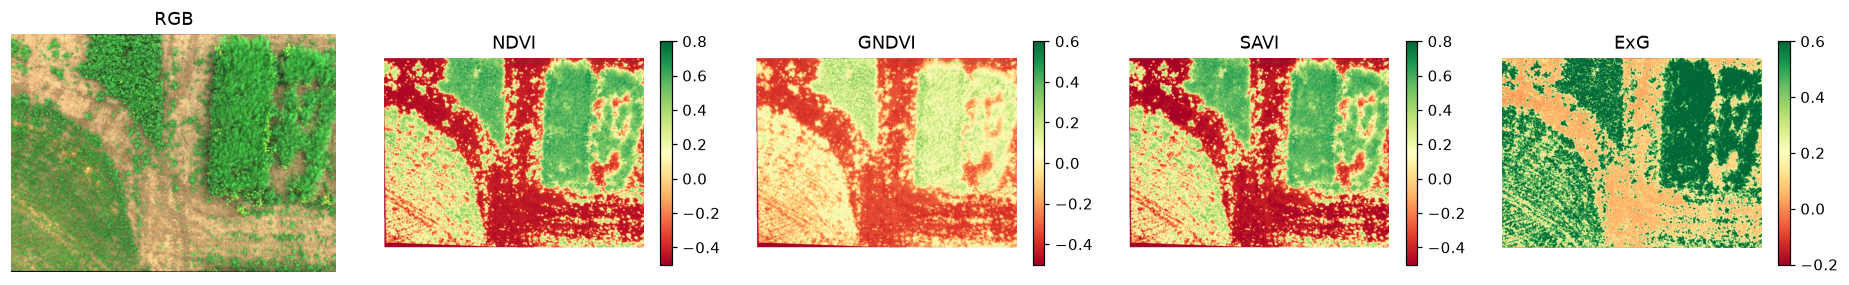

In [7]:
pair = rs.uav.load_pair(r.rgb_path, r.nir_path, register="sift")
vi = rs.uav.vegetation_indices(pair, ["NDVI", "GNDVI", "SAVI", "ExG"])
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2))
axes[0].imshow(rs.uav.to_rgb_array(pair)); axes[0].set_title("RGB")
for ax, name, lim in zip(axes[1:], ["NDVI", "GNDVI", "SAVI", "ExG"], [(-0.5, 0.8), (-0.5, 0.6), (-0.5, 0.8), (-0.2, 0.6)]):
    im = ax.imshow(vi[name], cmap="RdYlGn", vmin=lim[0], vmax=lim[1]); ax.set_title(name)
    plt.colorbar(im, ax=ax, shrink=0.7)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

**NDVI vs ExG for soil/vegetation separation.** Both are thresholded with Otsu; the 2-D
histogram shows how each separates the two classes.


cover NDVI 0.512, ExG 0.489; pixel agreement 91.2%


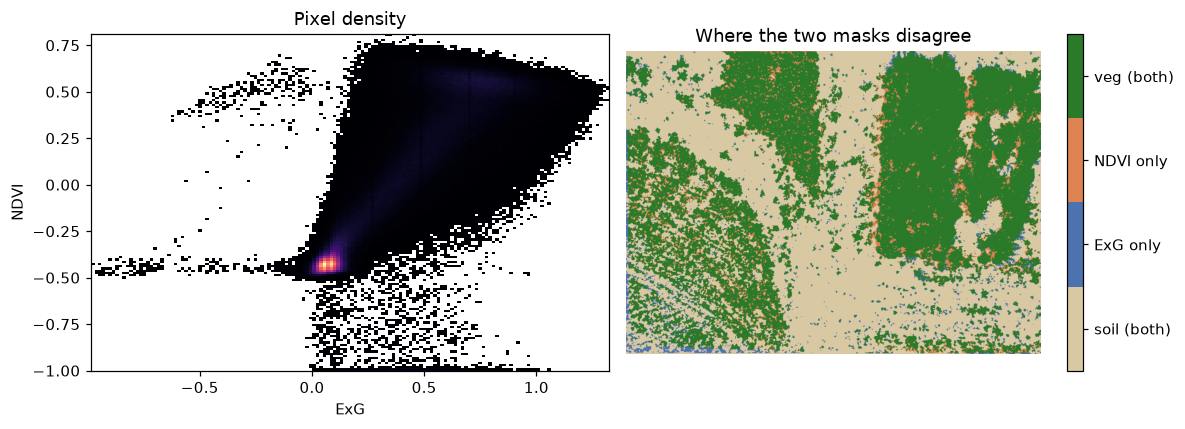

In [8]:
m_ndvi, c_ndvi = rs.uav.canopy_cover(vi.NDVI)
m_exg, c_exg = rs.uav.canopy_cover(vi.ExG)
agree = float((m_ndvi == m_exg).mean())
print(f"cover NDVI {c_ndvi:.3f}, ExG {c_exg:.3f}; pixel agreement {agree:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x, y = vi.ExG.values.ravel(), vi.NDVI.values.ravel(); ok = np.isfinite(x) & np.isfinite(y)
axes[0].hist2d(x[ok], y[ok], bins=150, cmap="magma", cmin=1)
axes[0].set(xlabel="ExG", ylabel="NDVI", title="Pixel density")
both = m_ndvi.values.astype(int) * 2 + m_exg.values.astype(int)  # 0 none, 1 ExG only, 2 NDVI only, 3 both
im = axes[1].imshow(both, cmap=plt.matplotlib.colors.ListedColormap(["#d9c9a3", "#4c72b0", "#dd8452", "#2a7a2a"]), vmin=-0.5, vmax=3.5)
cb = plt.colorbar(im, ax=axes[1], ticks=[0, 1, 2, 3]); cb.ax.set_yticklabels(["soil (both)", "ExG only", "NDVI only", "veg (both)"])
axes[1].set_title("Where the two masks disagree"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## Relative vs calibrated reflectance

The NIR and RGB cameras have different sensitivities, exposure settings and gains. A DN of
150 in NIR is not comparable to 150 in red, so DN-based NDVI is shifted and scaled by an
unknown amount, and it shifts again whenever exposure or sunlight changes. Look at the
distribution of NDVI medians per Drybean frame: in some sessions most pixels are negative,
which real vegetation reflectance would never produce.


In [9]:
bean = pairs[pairs.crop == "drybean"].groupby("session").sample(4, random_state=0)
meds = []
for _, rr in bean.iterrows():
    p = rs.uav.load_pair(rr.rgb_path, rr.nir_path)
    meds.append({"session": rr.session, "nir_mean_DN": float(p.sel(band="nir").mean()) * 255,
                 "red_mean_DN": float(p.sel(band="red").mean()) * 255,
                 "ndvi_median": float(rs.uav.vegetation_indices(p, "NDVI").median())})
pd.DataFrame(meds).groupby("session").mean().round(2)

,nir_mean_DN,red_mean_DN,ndvi_median
session,,,
drybean-04072020,73.80,121.53,-0.39
drybean-06082020,119.41,106.02,0.13
drybean-14062020,129.07,163.46,-0.11
drybean-20082020,110.28,87.93,0.11
drybean-25062020,100.37,160.74,-0.26
drybean-30072020,104.47,119.99,-0.21


Calibration converts DN to reflectance. The cell below builds a **synthetic** example on top
of a real pair: the pair is treated as "true" reflectance (scaled to realistic levels), a
camera with a different gain and dark offset per band turns it into DN, and two reflectance
panels (a 50 % grey and a 5 % black, as on commercial calibration targets) are pasted into
the scene. Calibration then has to recover the truth.


In [10]:
true = pair.copy() * xr.DataArray([0.25, 0.30, 0.20, 0.55], dims="band", coords={"band": pair.band})  # reflectance scale
true = true.clip(0, 1)
panels = {"grey": ((20, 70, 20, 70), 0.50), "black": ((20, 70, 90, 140), 0.05)}  # (row0, row1, col0, col1), reflectance
for (r0, r1, c0, c1), rho in panels.values():
    true[:, r0:r1, c0:c1] = rho

gain = {"red": 380.0, "green": 300.0, "blue": 420.0, "nir": 210.0}  # DN per unit reflectance
dark = {"red": 12.0, "green": 10.0, "blue": 15.0, "nir": 22.0}      # dark offset (DN)
dn = xr.Dataset({b: (true.sel(band=b, drop=True) * gain[b] + dark[b]).clip(0, 255) for b in gain})
truth = xr.Dataset({b: true.sel(band=b, drop=True) for b in gain})

grey_dn = rs.uav.panel_dn_from_image(dn, panels["grey"][0])
black_dn = rs.uav.panel_dn_from_image(dn, panels["black"][0])
one_panel = rs.uav.panel_calibration(dn, grey_dn, {b: 0.50 for b in gain})
two_panel, fits = rs.uav.empirical_line(dn, {b: [black_dn[b], grey_dn[b]] for b in gain},
                                        {b: [0.05, 0.50] for b in gain})
print("empirical line fits (gain, offset, r2):", {b: tuple(round(v, 4) for v in f) for b, f in fits.items()})

def ndvi(ds):
    return (ds.nir - ds.red) / (ds.nir + ds.red)

veg = (ndvi(truth) > 0.3).values
res = pd.DataFrame({
    "NDVI mean (vegetation)": [float(ndvi(x).values[veg].mean()) for x in (truth, dn, one_panel, two_panel)],
    "RMSE vs truth": [0.0] + [float(np.sqrt(np.nanmean((ndvi(x) - ndvi(truth)).values ** 2))) for x in (dn, one_panel, two_panel)],
}, index=["true reflectance", "raw DN", "one panel (gain only)", "empirical line (2 panels)"])
res.round(4)

empirical line fits (gain, offset, r2): {'red': (0.0026, -0.0316, 1.0), 'green': (0.0033, -0.0333, 1.0), 'blue': (0.0024, -0.0357, 1.0), 'nir': (0.0048, -0.1048, 1.0)}


,NDVI mean (vegetation),RMSE vs truth
true reflectance,0.6196,0.0000
raw DN,0.3864,0.2084
one panel (gain only),0.5609,0.0998
empirical line (2 panels),0.6196,0.0000


Raw-DN NDVI is biased because NIR and red have different gains and offsets. One panel fixes
the gain but not the dark offset; two panels (empirical line) recover the truth. Real panels
must be imaged at the flight's altitude and sun angle, and be large enough to cover many
pixels free of their edges.

**Changing light.** If clouds dim the sun by 30 % halfway through a flight, every DN drops.
A downwelling light sensor (DLS) on top of the drone records the irradiance per band, and
`rs.uav.sunshine_normalize` rescales each image to a reference irradiance:


In [11]:
E_ref = {"red": 1.00, "green": 1.00, "blue": 1.00, "nir": 1.00}  # irradiance at panel capture
E_cloud = {"red": 0.70, "green": 0.71, "blue": 0.74, "nir": 0.66}  # under a passing cloud (bluer, less NIR)
dim = xr.Dataset({b: (truth[b] * E_cloud[b] * gain[b] + dark[b]).clip(0, 255) for b in gain})
dim_corr = rs.uav.sunshine_normalize(xr.Dataset({b: dim[b] - dark[b] for b in gain}), E_cloud, E_ref)
dim_corr = xr.Dataset({b: dim_corr[b] + dark[b] for b in gain})  # put the dark offset back
cal_dim, _ = rs.uav.empirical_line(dim, {b: [black_dn[b], grey_dn[b]] for b in gain}, {b: [0.05, 0.50] for b in gain})
cal_fix, _ = rs.uav.empirical_line(dim_corr, {b: [black_dn[b], grey_dn[b]] for b in gain}, {b: [0.05, 0.50] for b in gain})
pd.Series({"cloudy, panel from sunny time": float(np.sqrt(np.nanmean((ndvi(cal_dim) - ndvi(truth)).values ** 2))),
           "cloudy, DLS-normalised first": float(np.sqrt(np.nanmean((ndvi(cal_fix) - ndvi(truth)).values ** 2)))},
          name="NDVI RMSE").round(4).to_frame()

,NDVI RMSE
"cloudy, panel from sunny time",0.0235
"cloudy, DLS-normalised first",0.0000


The dark offset is removed before scaling because irradiance only multiplies the signal, not
the sensor's dark current.


## NDVI trajectories for four crops

Without panels the indices below are relative, so compare **within** a crop and keep the
caveat in mind when comparing crops. For each session, 10 random pairs are registered with
SIFT (`refine=False` for speed) and summarised inside the vegetation mask.


In [12]:
def pair_traits(rr):
    p = rs.uav.load_pair(rr.rgb_path, rr.nir_path, register="sift", refine=False)
    v = rs.uav.vegetation_indices(p, ["NDVI", "GNDVI", "ExG"])
    mask, cover = rs.uav.canopy_cover(v.ExG)
    return {"ndvi_veg": float(v.NDVI.where(mask).mean()), "gndvi_veg": float(v.GNDVI.where(mask).mean()),
            "ndvi_all": float(v.NDVI.median()), "cover_exg": cover,
            "inliers": p.attrs.get("register_inliers", np.nan),
            "registered": bool(p.attrs.get("register_accepted", False))}

sample = pairs.groupby(["session", "rig"], dropna=False).sample(10, random_state=0, replace=False)
rows = []
for _, rr in sample.iterrows():
    try:
        rows.append({"crop": rr.crop, "session": rr.session, "date": rr.date, **pair_traits(rr)})
    except Exception as e:  # featureless frames can fail to register
        print("skip", rr.rgb_path, "-", e)
traj = pd.DataFrame(rows)
print(f"registration accepted for {traj.registered.mean():.0%} of {len(traj)} pairs")
summ = rs.uav.summarize_dates(traj, ["ndvi_veg", "gndvi_veg", "cover_exg"])
summ.round(3)

registration accepted for 99% of 180 pairs


,crop,date,ndvi_veg_mean,ndvi_veg_std,ndvi_veg_count,gndvi_veg_mean,gndvi_veg_std,gndvi_veg_count,cover_exg_mean,cover_exg_std,cover_exg_count
0,canola,2018-07-30,0.432,0.056,10,0.187,0.063,10,0.471,0.098,10
1,canola,2018-08-31,0.199,0.057,10,0.151,0.045,10,0.318,0.217,10
2,canola,2019-07-26,0.490,0.024,10,0.123,0.043,10,0.456,0.063,10
3,canola,2019-08-06,0.467,0.110,10,0.155,0.179,10,0.519,0.195,10
4,drybean,2020-06-14,0.153,0.105,20,0.055,0.064,20,0.125,0.197,20
5,drybean,2020-06-25,0.215,0.207,10,0.030,0.113,10,0.110,0.214,10
6,drybean,2020-07-04,0.356,0.052,10,-0.007,0.070,10,0.154,0.066,10
7,drybean,2020-07-30,0.471,0.057,10,0.119,0.037,10,0.427,0.093,10
8,drybean,2020-08-06,0.418,0.067,20,0.141,0.055,20,0.355,0.086,20
9,drybean,2020-08-20,0.349,0.088,20,0.078,0.072,20,0.394,0.104,20


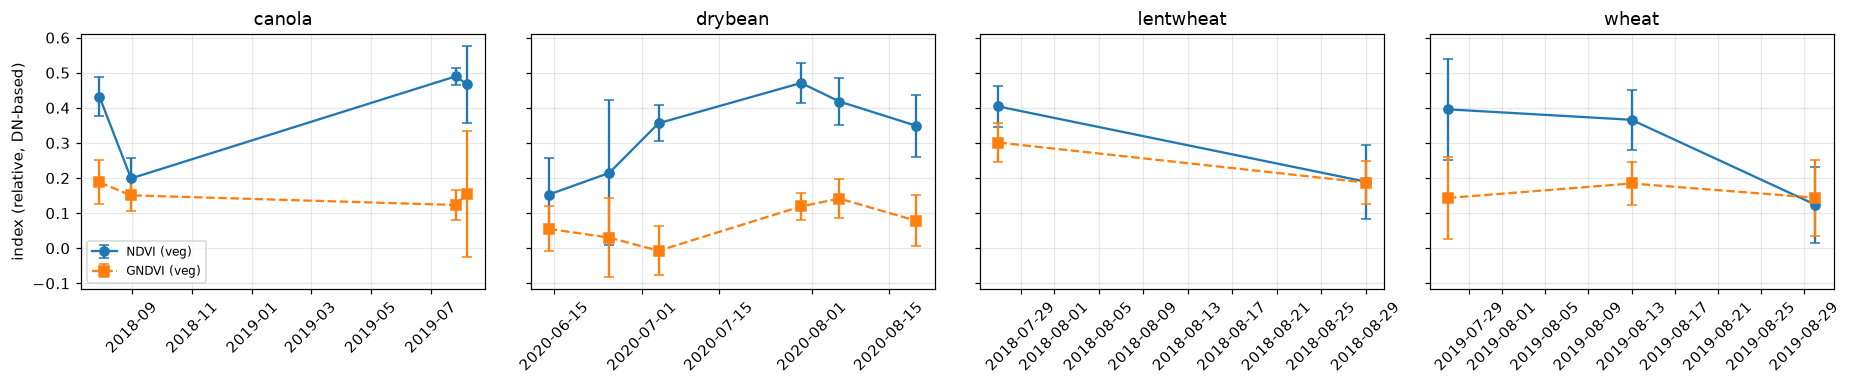

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, (crop, d) in zip(axes, summ.groupby("crop")):
    ax.errorbar(d.date, d.ndvi_veg_mean, yerr=d.ndvi_veg_std, fmt="o-", capsize=3, label="NDVI (veg)")
    ax.errorbar(d.date, d.gndvi_veg_mean, yerr=d.gndvi_veg_std, fmt="s--", capsize=3, label="GNDVI (veg)")
    ax.set_title(crop); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("index (relative, DN-based)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
traj.to_csv(OUT / "crop_ndvi_pairs.csv", index=False)

Read these curves with care. Each date is a separate flight with its own exposure, so part
of a date-to-date change can be radiometric rather than biological; panels or a DLS would
separate the two. Canola and Wheat span two different years, so their dates do not form a
single season.


## Summary and exercises

**Key points**

- A two-camera rig does not share one footprint. Register NIR to RGB (`coregister`) before
  computing an index, and check the fit with edge agreement.
- NDVI, GNDVI and SAVI need NIR. On raw digital numbers they stay relative until a
  calibration converts them.
- A panel, an empirical line and a sunshine correction are the three steps from DN toward
  reflectance.
- Follow NDVI by crop and date only after the pairs that failed registration have been dropped.

**GeoLattice functions used:** `rs.uav.load_pair`, `rs.uav.coregister`, `rs.uav.estimate_homography`,
`rs.uav.edge_agreement`, `rs.uav.vegetation_indices`, `rs.uav.panel_calibration`,
`rs.uav.panel_dn_from_image`, `rs.uav.empirical_line`, `rs.uav.sunshine_normalize`,
`rs.uav.summarize_dates`.

**Exercises**

1. Register 20 Lentil-Wheat pairs with ORB and with SIFT. How often does validation reject
   each one, and for which reason?
2. Add a third panel (20 %) to the synthetic example. Does the empirical line still give
   `r2` close to 1? What happens if the black panel is partly in shadow (add 15 DN)?
3. Replace NDVI with SAVI in Section 6. Does the soil-adjusted index change the early-season
   Drybean values more than the late ones?
4. Compute per-session NIR and red DN means and plot them against NDVI. How much of the NDVI
   change between dates follows exposure?

**References**

- Rouse, J. W. et al. (1974). Monitoring vegetation systems in the Great Plains with ERTS.
  *Third ERTS Symposium*, NASA SP-351, 309-317 (NDVI).
- Gitelson, A. A. et al. (1996). Use of a green channel in remote sensing of global
  vegetation from EOS-MODIS. *Remote Sensing of Environment*, 58, 289-298 (GNDVI).
- Huete, A. R. (1988). A soil-adjusted vegetation index (SAVI). *Remote Sensing of
  Environment*, 25, 295-309.
- Smith, G. M. and Milton, E. J. (1999). The use of the empirical line method to calibrate
  remotely sensed data to reflectance. *International Journal of Remote Sensing*, 20, 2653-2662.
- Evangelidis, G. D. and Psarakis, E. Z. (2008). Parametric image alignment using enhanced
  correlation coefficient maximization. *IEEE TPAMI*, 30, 1858-1865.
